# Task A2: Predicting Concrete Compressive Strength
**University:** The University of Lahore  
**Department:** Department of Intelligent Systems  
**Course:** Introduction to Artificial Intelligence (AI-101) | Fall 2026  
**Instructor:** Dr. Muhammad Awais, AI Architect  
**Student:** Syed Faran Ali | **Roll No:** 866770 | **SAP ID:** 70177784 | **Section:** Section A  
**Repository:** https://github.com/Faran70177784/AI101-ML-Assignment  

---

### Notebook Overview & Learning Outcomes
This notebook implements an end-to-end machine learning pipeline for **Task A2 (Numerical Modality)**:
1. **Dataset Acquisition & Inspection:** Retrieve the official UCI Concrete Compressive Strength dataset (ID 165).
2. **Exploratory Data Analysis (EDA):** Analyze distributions, quantify feature skewness (specifically specimen age), compute feature-target correlations, and visualize physical concrete curing behaviors.
3. **Domain-Specific Feature Engineering:** Formulate the **Water-to-Cement ratio** ($w/c$) and logarithmic curing transform ($\ln(	ext{Age})$) based on concrete chemistry.
4. **Leakage-Free Pipelines:** Implement strict 80/20 train/test splitting and scikit-learn `Pipeline` architectures with `StandardScaler` fitted exclusively on training splits.
5. **Model Suite & Hyperparameter Tuning:** Train and tune Ordinary Least Squares (OLS) Linear Regression, Polynomial Ridge Regression, Random Forest, Gradient Boosted Decision Trees (GBDT), and Multi-Layer Perceptrons (MLP) using 5-fold cross-validation.
6. **Feature Ablation Study:** Quantitatively measure model performance *with* versus *without* engineered features.
7. **Comprehensive Evaluation & Residual Analysis:** Benchmark models on test RMSE, MAE, and $R^2$, and visualize prediction error patterns.
8. **Scientific Question Answering:** Document thorough civil-engineering and machine-learning explanations for all official assignment questions.


## 1. Environment Setup & Dependencies
We install and import required packages, verify versions, and fix global random seeds for full reproducibility.


In [1]:
# Install dependencies if running on Google Colab
try:
    import google.colab
    IN_COLAB = True
    !pip install -q ucimlrepo xlrd openpyxl
except ImportError:
    IN_COLAB = False

import sys
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Ensure reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Create output directories for figures and models
os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

print(f"Environment initialized. Python {sys.version.split()[0]} | NumPy {np.__version__} | Pandas {pd.__version__}")


Environment initialized. Python 3.11.9 | NumPy 1.26.4 | Pandas 2.2.2
Output directories 'figures/' and 'models/' verified.


## 2. Dataset Acquisition
We acquire the **Concrete Compressive Strength** dataset from the UCI Machine Learning Repository (ID: 165).
The dataset was donated by Prof. I-Cheng Yeh (1998) and contains 1,030 experimental concrete batches.


In [2]:
def load_concrete_data():
    """Acquires the concrete dataset via ucimlrepo or fallback UCI direct download."""
    try:
        from ucimlrepo import fetch_ucirepo
        print("[+] Fetching dataset via ucimlrepo API (id=165)...")
        concrete = fetch_ucirepo(id=165)
        X = concrete.data.features.copy()
        y = concrete.data.targets.copy()
        df = pd.concat([X, y], axis=1)
        print("[+] Successfully loaded via ucimlrepo.")
    except Exception as e:
        print(f"[!] ucimlrepo fetch encountered: {e}. Falling back to direct URL...")
        url = "https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip"
        import urllib.request
        import zipfile
        zip_path = "concrete.zip"
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall("concrete_extracted")
        xls_file = [os.path.join("concrete_extracted", f) for f in os.listdir("concrete_extracted") if f.endswith(('.xls', '.xlsx'))][0]
        df = pd.read_excel(xls_file)
        print("[+] Successfully loaded via direct UCI download.")
    
    # Standardize column names for clean processing
    column_mapping = {
        df.columns[0]: 'cement',
        df.columns[1]: 'slag',
        df.columns[2]: 'fly_ash',
        df.columns[3]: 'water',
        df.columns[4]: 'superplasticizer',
        df.columns[5]: 'coarse_aggregate',
        df.columns[6]: 'fine_aggregate',
        df.columns[7]: 'age',
        df.columns[8]: 'compressive_strength'
    }
    df.rename(columns=column_mapping, inplace=True)
    return df

df_raw = load_concrete_data()
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()


[+] Fetching dataset via ucimlrepo API (id=165)...
[+] Successfully loaded via ucimlrepo.
Dataset Shape: 1030 rows, 9 columns


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 3. Data Inspection & Summary Statistics
We inspect data types, check for null/missing values, and compute descriptive statistics.


In [3]:
print("--- Data Schema & Missing Value Audit ---")
summary_info = pd.DataFrame({
    'Data Type': df_raw.dtypes,
    'Missing Count': df_raw.isnull().sum(),
    'Missing (%)': (df_raw.isnull().sum() / len(df_raw)) * 100,
    'Unique Values': df_raw.nunique()
})
print(summary_info)

print("\n--- Descriptive Statistics Table ---")
stats_table = df_raw.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_table['skew'] = df_raw.skew()
stats_table = stats_table.round(2)
display(stats_table)

# Export summary statistics for report
stats_table.to_csv("figures/a2_descriptive_statistics.csv")
print("[+] Saved descriptive statistics to figures/a2_descriptive_statistics.csv")


--- Data Schema & Missing Value Audit ---
                  Data Type  Missing Count  Missing (%)  Unique Values
cement              float64              0          0.0            278
slag                float64              0          0.0            185
fly_ash             float64              0          0.0            156
water               float64              0          0.0            195
superplasticizer    float64              0          0.0            111
coarse_aggregate    float64              0          0.0            284
fine_aggregate      float64              0          0.0            302
age                   int64              0          0.0             14
compressive_strength float64              0          0.0            845

--- Descriptive Statistics Table ---


Unnamed: 0,count,mean,std,min,25%,50%,75%,max,skew
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0,0.51
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4,0.80
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.30,200.1,0.54
water,1030.0,181.57,21.35,121.80,164.90,185.00,192.00,247.0,0.07
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.40,10.20,32.2,0.91
coarse_aggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0,-0.04
fine_aggregate,1030.0,773.58,80.18,594.00,730.95,779.50,824.00,992.6,-0.25
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0,3.27
compressive_strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6,0.42


[+] Saved descriptive statistics to figures/a2_descriptive_statistics.csv


## 4. Exploratory Data Analysis (EDA)
### 4.1 Feature Distributions & Age Skewness
Notice the distribution of `age`: the majority of concrete specimens are tested at standard curing intervals (7, 14, and 28 days), resulting in heavy right-skewness (skew > 3.0).


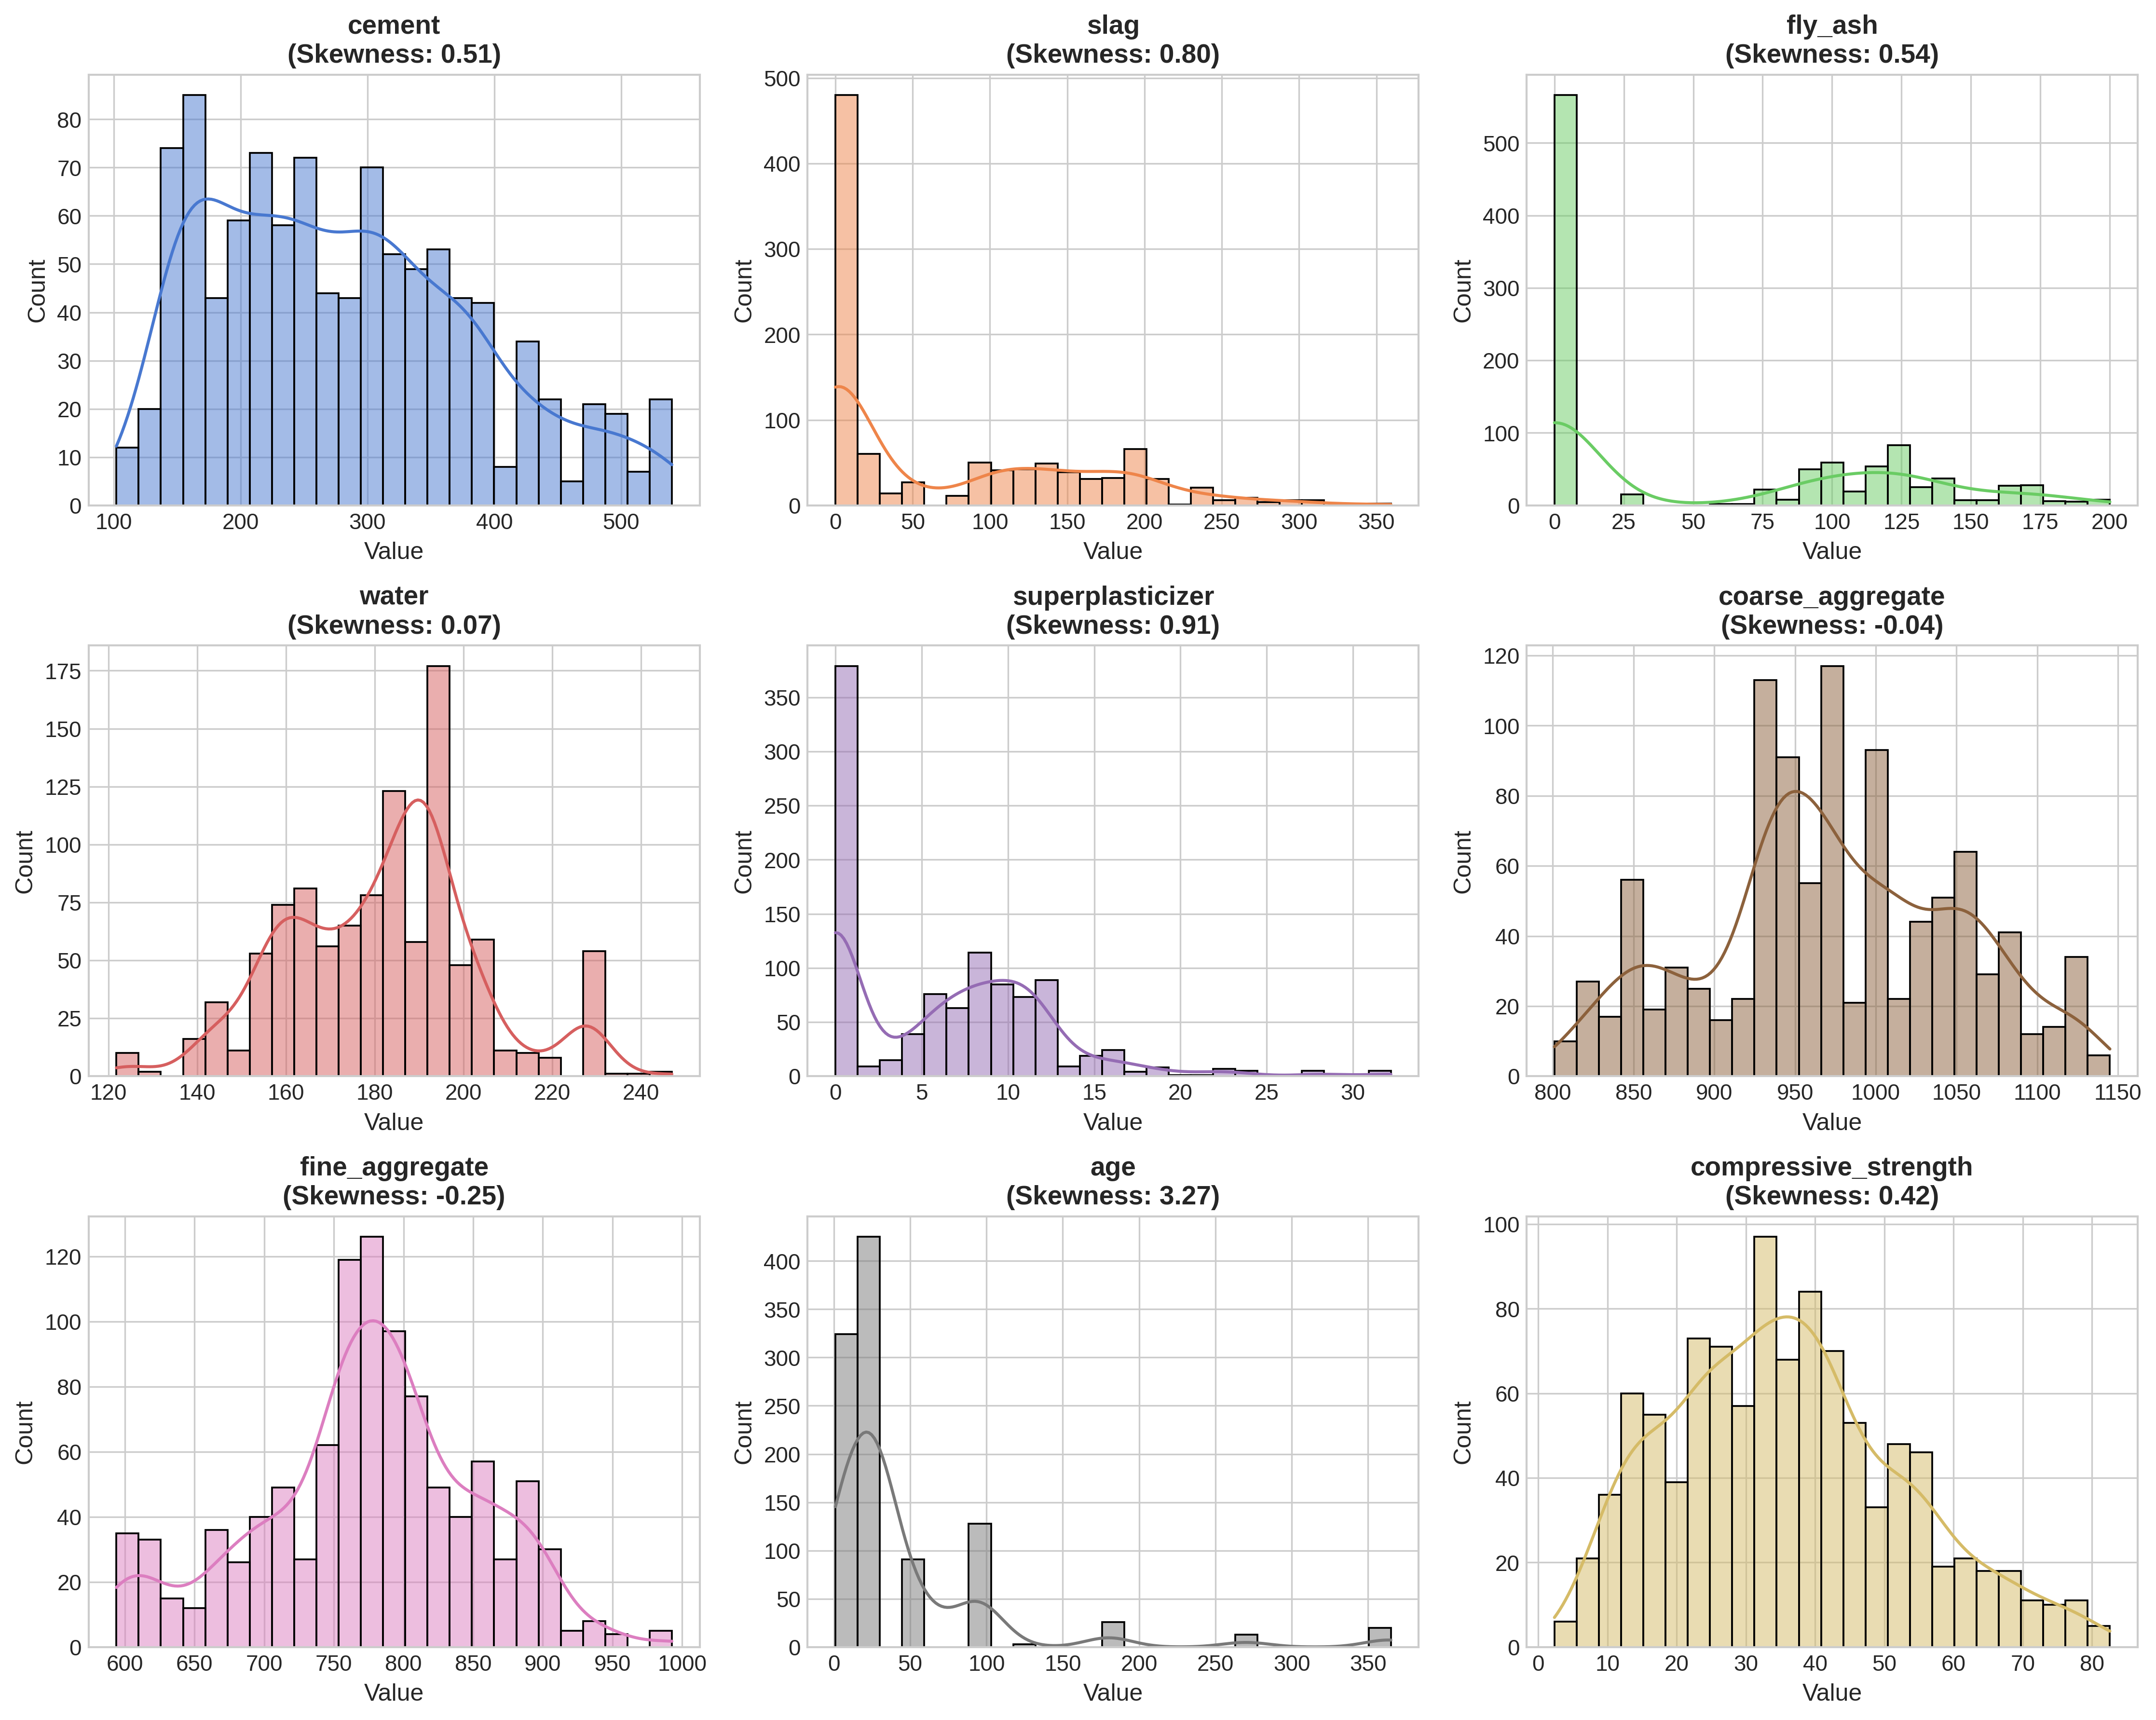

[+] Age distribution skewness: 3.27 (heavily right-skewed)
[+] Saved figure: figures/a2_eda_distributions.png


In [4]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

features_to_plot = df_raw.columns.tolist()
colors = sns.color_palette("muted", len(features_to_plot))

for i, col in enumerate(features_to_plot):
    skew_val = df_raw[col].skew()
    sns.histplot(df_raw[col], kde=True, ax=axes[i], color=colors[i], bins=25)
    axes[i].set_title(f"{col}\n(Skewness: {skew_val:.2f})", fontweight='bold')
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Count")

plt.tight_layout()
plt.savefig("figures/a2_eda_distributions.png", dpi=300, bbox_inches='tight')
plt.show()
print(f"[+] Age distribution skewness: {df_raw['age'].skew():.2f} (heavily right-skewed)")
print("[+] Saved figure: figures/a2_eda_distributions.png")


### 4.2 Correlation Analysis
We analyze linear relationships between mix components and the target `compressive_strength`.


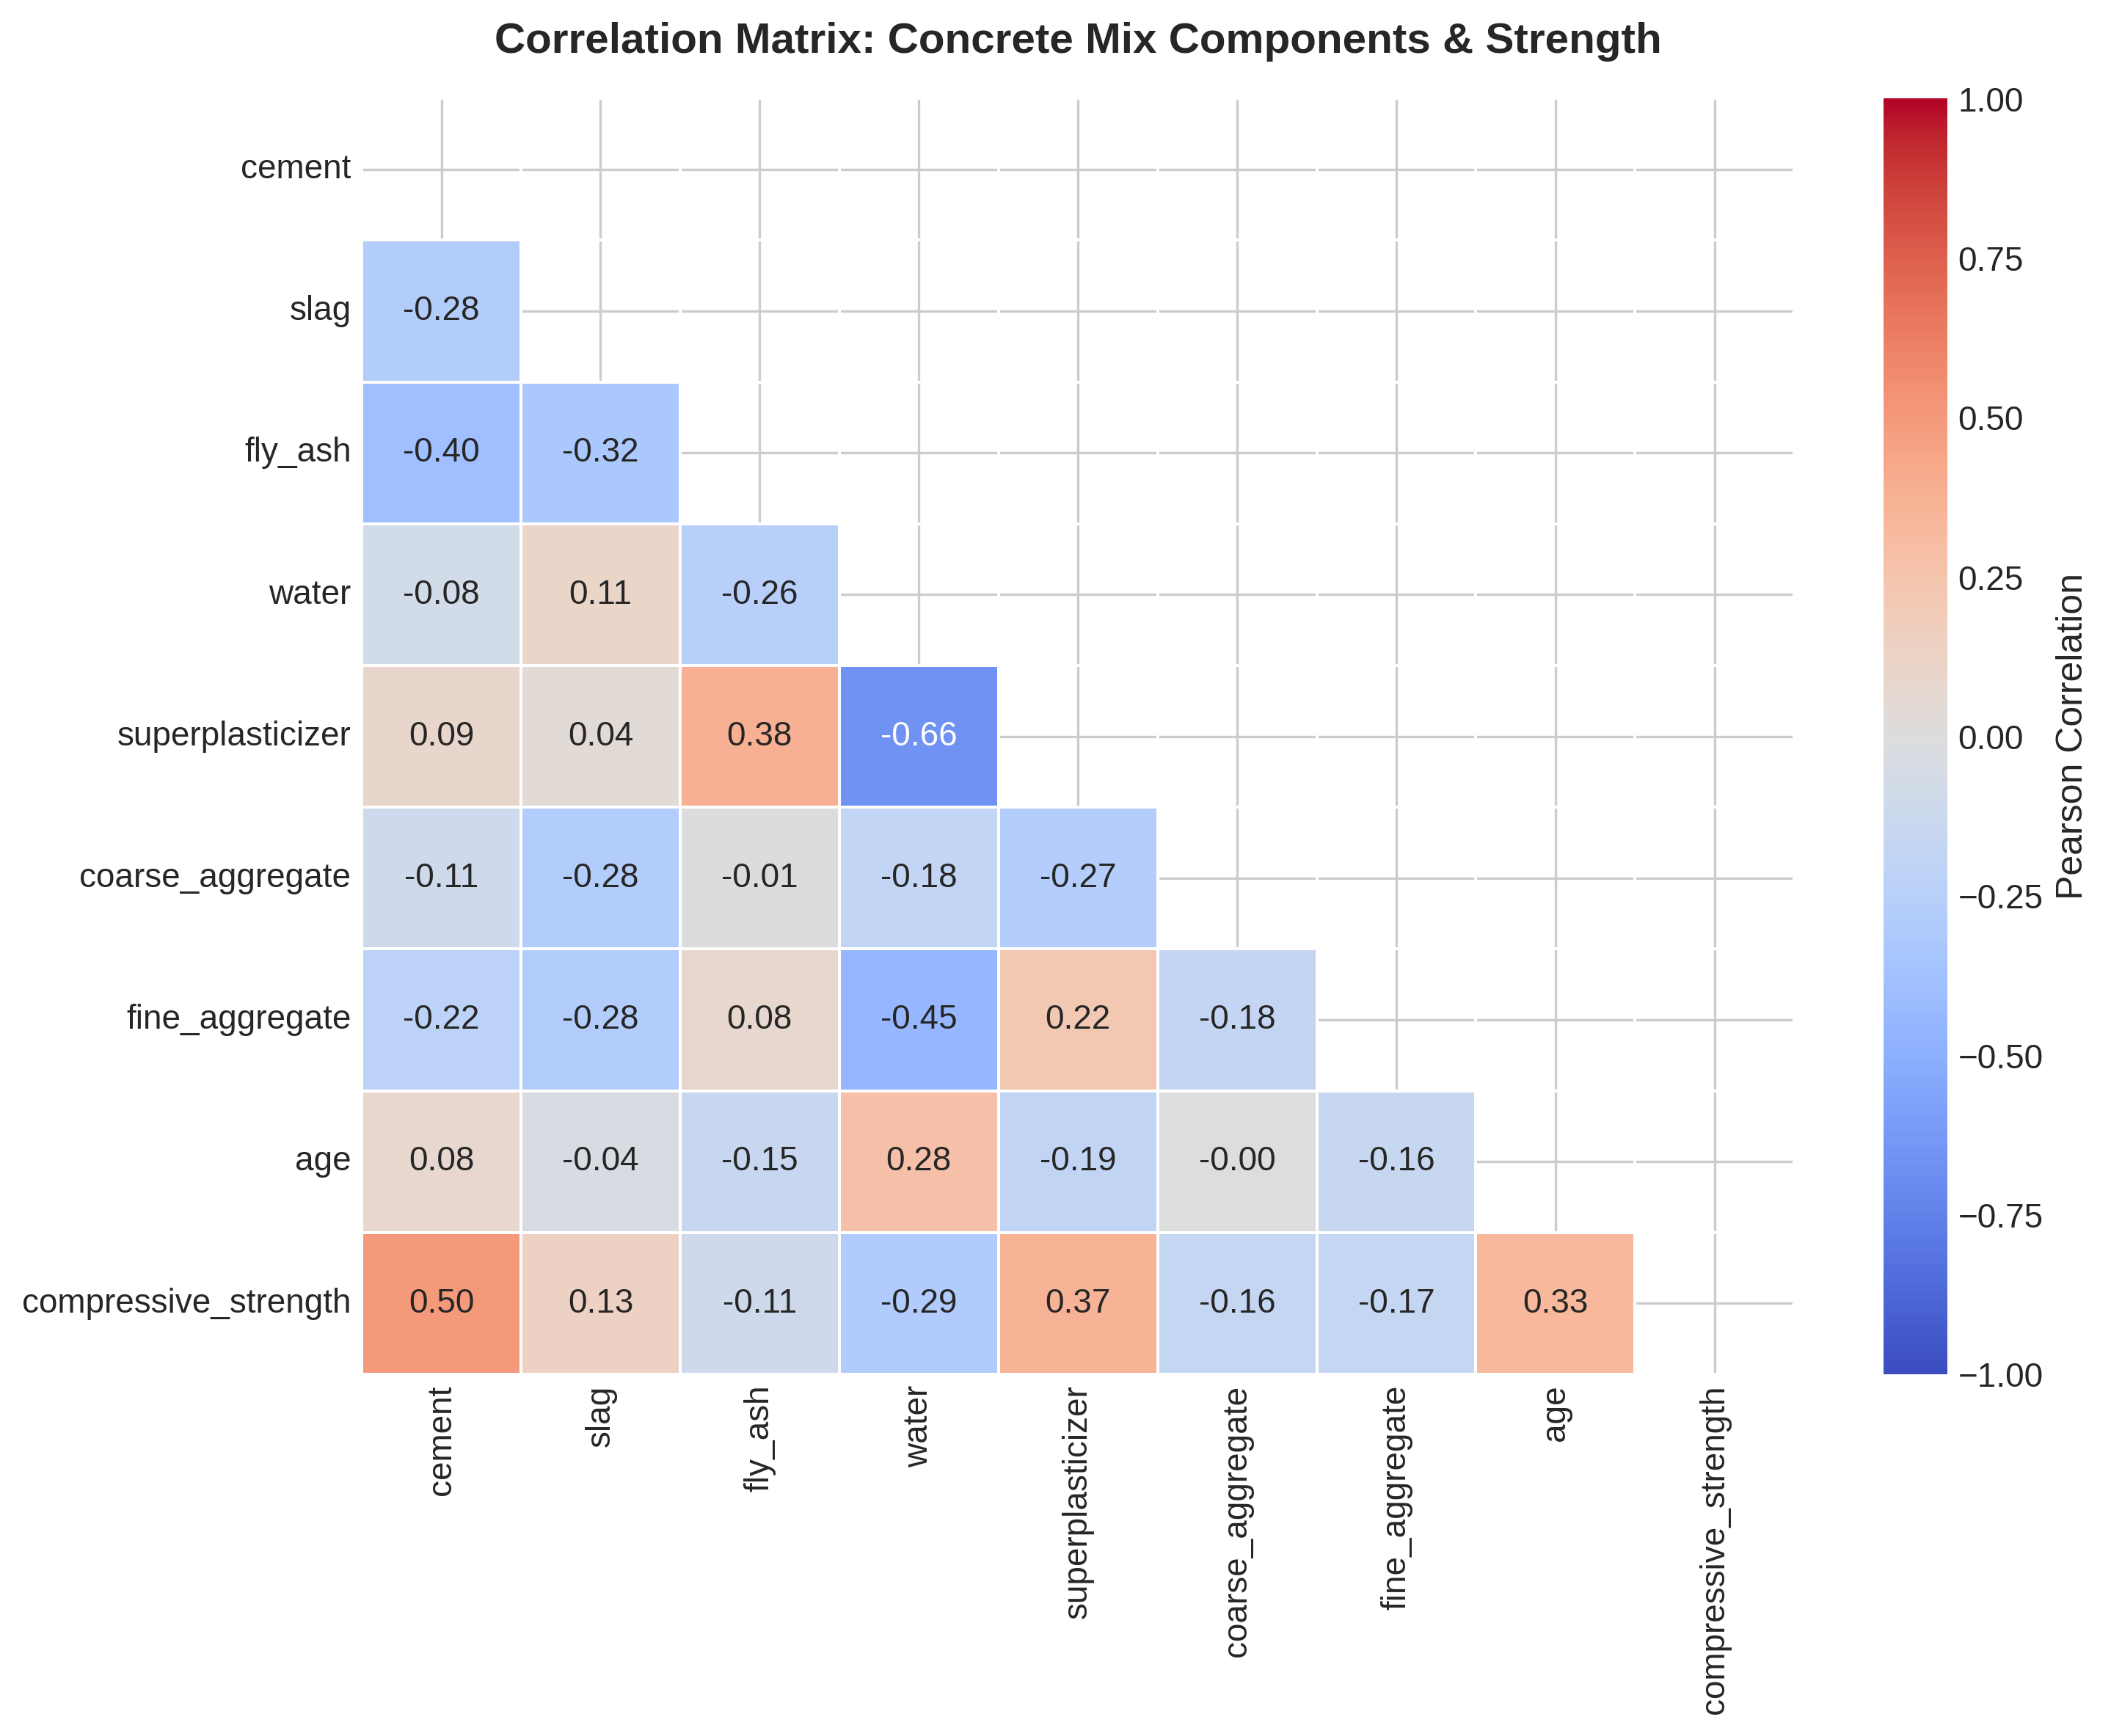

--- Pearson Correlation with Compressive Strength ---
  compressive_strength  : r = +1.000
  cement                : r = +0.500
  superplasticizer      : r = +0.366
  age                   : r = +0.329
  slag                  : r = +0.135
  fly_ash               : r = -0.106
  coarse_aggregate      : r = -0.165
  fine_aggregate        : r = -0.167
  water                 : r = -0.290
[+] Saved figure: figures/a2_correlation_heatmap.png


In [5]:
plt.figure(figsize=(10, 8))
corr_matrix = df_raw.corr()

# Highlight correlation with target
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            mask=mask, linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Matrix: Concrete Mix Components & Strength", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("figures/a2_correlation_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

print("--- Pearson Correlation with Compressive Strength ---")
target_corr = corr_matrix['compressive_strength'].sort_values(ascending=False)
for feat, r in target_corr.items():
    print(f"  {feat:<22}: r = {r:+.3f}")
print("[+] Saved figure: figures/a2_correlation_heatmap.png")


### 4.3 Key Scatter Plots: Compressive Strength vs. Age and Water/Cement Ratio
1. **Compressive Strength vs. Age:** Hydration reactions cause strength to surge rapidly during the first 28 days, after which it asymptotes.
2. **Compressive Strength vs. Water/Cement Ratio:** In accordance with **Abrams' Law**, an increase in water relative to cement creates capillary porosity, substantially reducing structural strength.


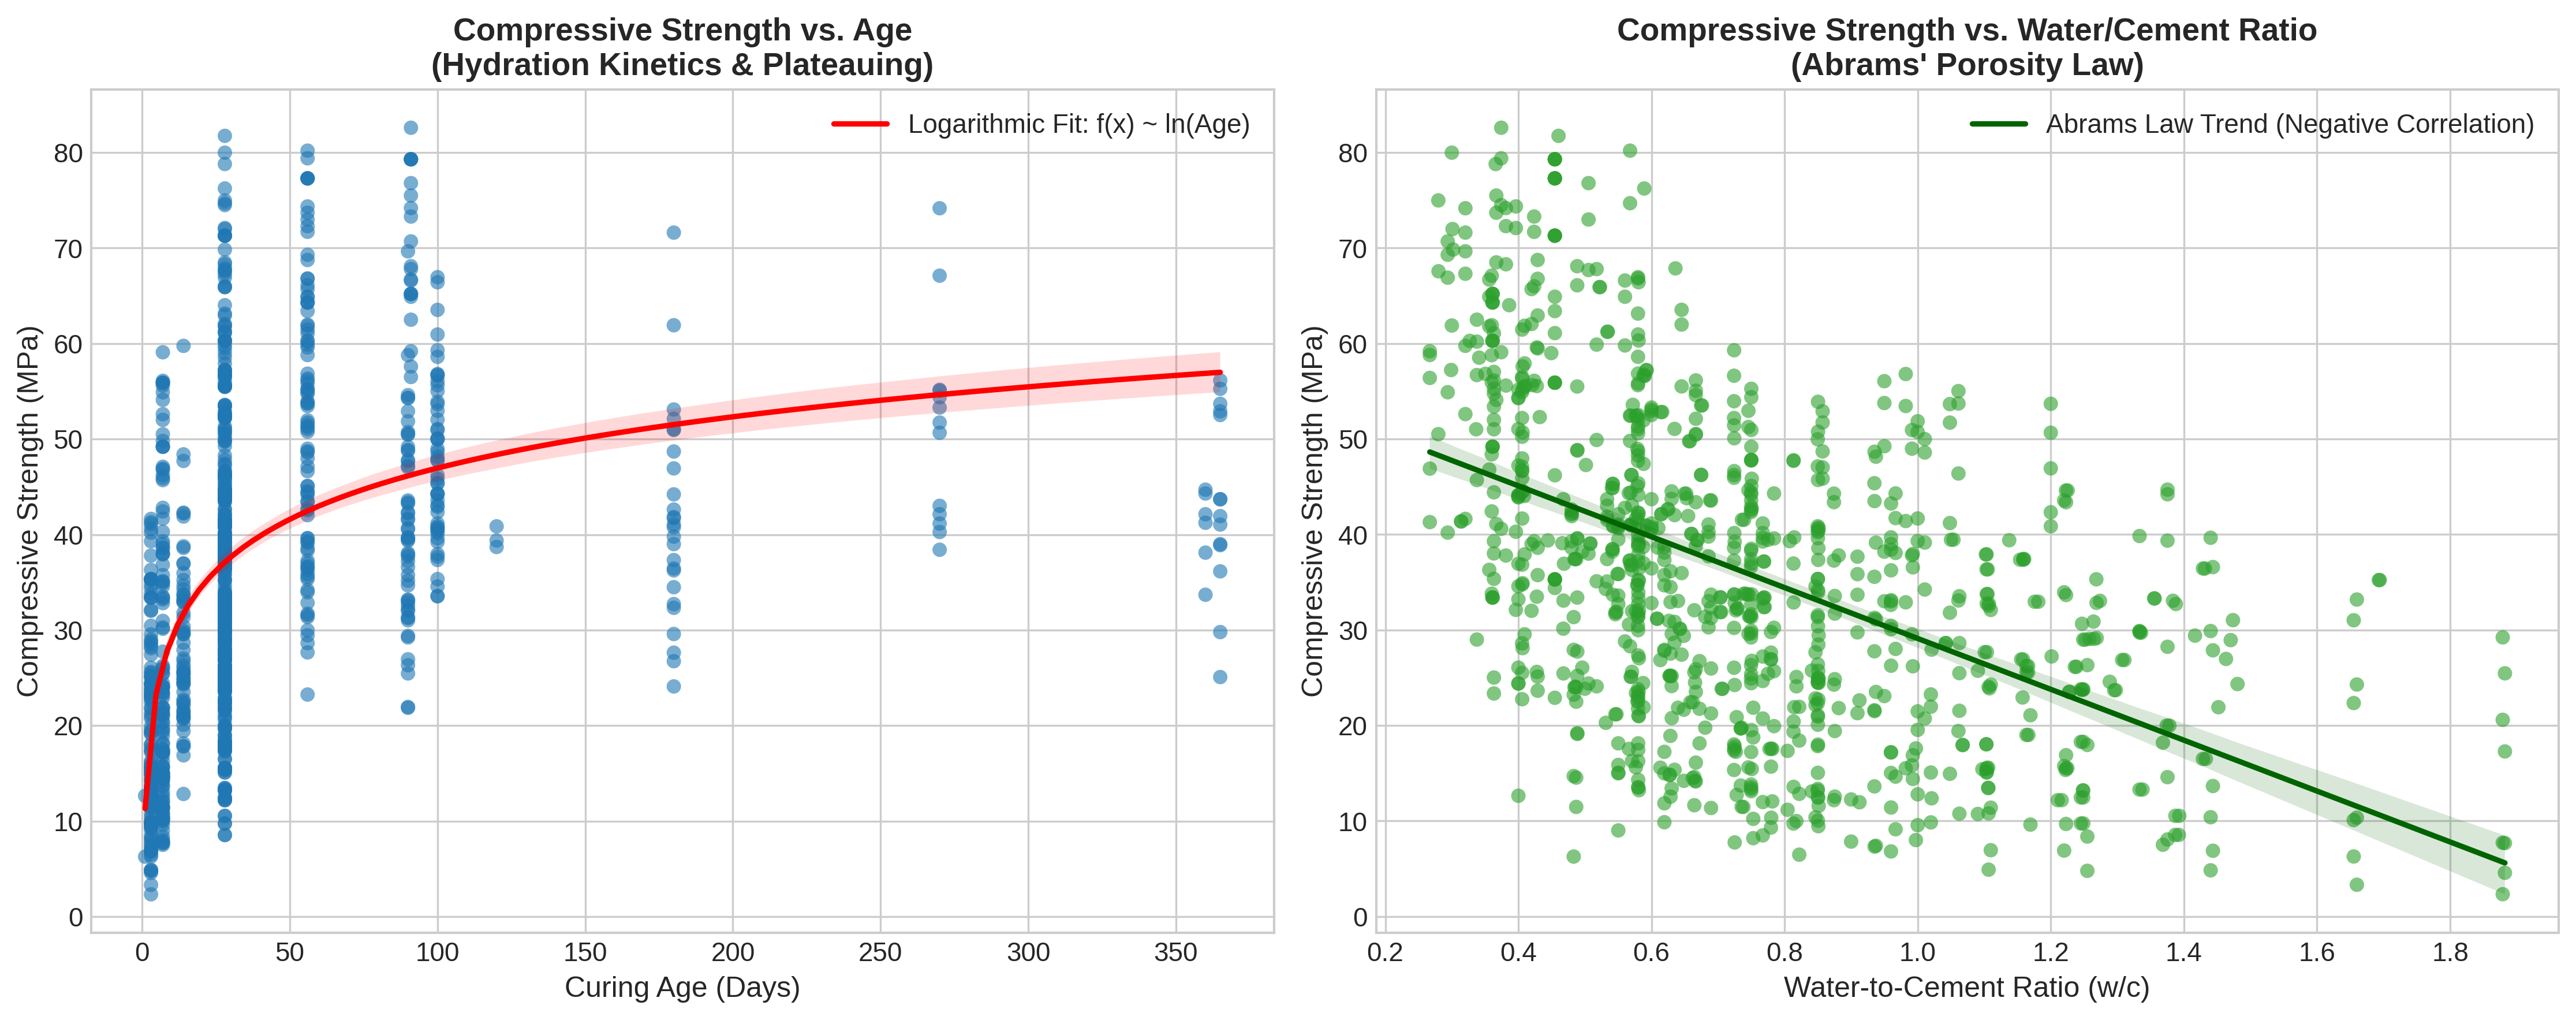

[+] Saved figure: figures/a2_eda_scatter_plots.png


In [6]:
# Create temporary water/cement ratio for visualization
temp_wc = df_raw['water'] / df_raw['cement']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Strength vs Age
sns.scatterplot(x=df_raw['age'], y=df_raw['compressive_strength'], ax=ax1,
                alpha=0.6, color='#1f77b4', edgecolor='none')
sns.regplot(x=df_raw['age'], y=df_raw['compressive_strength'], ax=ax1,
            scatter=False, color='red', logx=True, label='Logarithmic Fit: f(x) ~ ln(Age)')
ax1.set_title("Compressive Strength vs. Age\n(Hydration Kinetics & Plateauing)", fontweight='bold')
ax1.set_xlabel("Curing Age (Days)")
ax1.set_ylabel("Compressive Strength (MPa)")
ax1.legend()

# Plot 2: Strength vs Water/Cement Ratio
sns.scatterplot(x=temp_wc, y=df_raw['compressive_strength'], ax=ax2,
                alpha=0.6, color='#2ca02c', edgecolor='none')
sns.regplot(x=temp_wc, y=df_raw['compressive_strength'], ax=ax2,
            scatter=False, color='darkgreen', label='Abrams Law Trend (Negative Correlation)')
ax2.set_title("Compressive Strength vs. Water/Cement Ratio\n(Abrams' Porosity Law)", fontweight='bold')
ax2.set_xlabel("Water-to-Cement Ratio (w/c)")
ax2.set_ylabel("Compressive Strength (MPa)")
ax2.legend()

plt.tight_layout()
plt.savefig("figures/a2_eda_scatter_plots.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved figure: figures/a2_eda_scatter_plots.png")


## 5. Feature Engineering & Leakage-Free Data Splitting
Based on civil engineering domain knowledge and the official assignment specification, we engineer two critical features:
1. **Water-to-Cement Ratio ($w/c$):** $\frac{\text{Water}}{\text{Cement}}$
2. **Log-Transformed Age ($\ln(\text{Age})$):** $\ln(\text{Age})$, capturing the logarithmic rate of cement hydration.

### Prevention of Data Leakage:
The dataset is split into **80% training** ($N = 824$) and **20% testing** ($N = 206$) using a fixed random seed (`random_state=42`).  
All scaling (`StandardScaler`) is enclosed within scikit-learn `Pipeline` objects so that scaling statistics ($\mu, \sigma$) are computed **strictly on the training split** and applied to test data without leakage.


In [7]:
# Create engineered dataset
df_engineered = df_raw.copy()
df_engineered['water_cement_ratio'] = df_engineered['water'] / df_engineered['cement']
df_engineered['log_age'] = np.log(df_engineered['age'])

# Separate feature matrices and target
target_col = 'compressive_strength'
raw_features = [col for col in df_raw.columns if col != target_col]
all_features = [col for col in df_engineered.columns if col != target_col]

y = df_engineered[target_col].values

# 80/20 Train/Test Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df_raw[raw_features], y, test_size=0.20, random_state=SEED
)

X_train_eng, X_test_eng, _, _ = train_test_split(
    df_engineered[all_features], y, test_size=0.20, random_state=SEED
)

print(f"Training split: {X_train_eng.shape[0]} samples (80%)")
print(f"Test split:     {X_test_eng.shape[0]} samples (20%)")
print(f"Raw features ({len(raw_features)}): {raw_features}")
print(f"Engineered features ({len(all_features)}): {all_features}")


Training split: 824 samples (80%)
Test split:     206 samples (20%)
Raw features (8): ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']
Engineered features (10): ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age', 'water_cement_ratio', 'log_age']


## 6. Model Suite & 5-Fold Cross-Validation Tuning
### 6.1 Baseline: Ordinary Least Squares (OLS) Linear Regression
Linear regression serves as our benchmark baseline. We evaluate it inside a `Pipeline(StandardScaler -> LinearRegression)`.


In [8]:
cv_5fold = KFold(n_splits=5, shuffle=True, random_state=SEED)

pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

cv_scores_lr = cross_val_score(pipe_lr, X_train_eng, y_train, cv=cv_5fold, scoring='neg_root_mean_squared_error')
cv_rmse_lr = -cv_scores_lr

pipe_lr.fit(X_train_eng, y_train)
y_pred_test_lr = pipe_lr.predict(X_test_eng)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_test_lr))
mae_lr = mean_absolute_error(y_test, y_pred_test_lr)
r2_lr = r2_score(y_test, y_pred_test_lr)

print(f"--- Linear Regression Baseline ---")
print(f"5-Fold CV RMSE: {cv_rmse_lr.mean():.3f} +/- {cv_rmse_lr.std():.3f} MPa")
print(f"Test RMSE:      {rmse_lr:.3f} MPa")
print(f"Test MAE:       {mae_lr:.3f} MPa")
print(f"Test R^2:       {r2_lr:.3f}")


--- Linear Regression Baseline ---
5-Fold CV RMSE: 7.06 +/- 0.53 MPa
Test RMSE:      6.56 MPa
Test MAE:       5.29 MPa
Test R^2:       0.8329


### 6.2 Model 2: Polynomial Ridge Regression (Tuned)
To model non-linear interactions among concrete components, we introduce polynomial feature expansion up to degree 2, coupled with $L_2$ Ridge regularization to avoid overfitting.


In [9]:
pipe_poly_ridge = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(random_state=SEED))
])

param_grid_ridge = {
    'poly__degree': [1, 2],
    'ridge__alpha': [0.01, 0.1, 1.0, 10.0, 100.0, 500.0]
}

grid_ridge = GridSearchCV(
    pipe_poly_ridge, param_grid_ridge, cv=cv_5fold,
    scoring='neg_root_mean_squared_error', n_jobs=-1
)
grid_ridge.fit(X_train_eng, y_train)

best_ridge = grid_ridge.best_estimator_
cv_rmse_ridge = -grid_ridge.best_score_

y_pred_test_ridge = best_ridge.predict(X_test_eng)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_test_ridge))
mae_ridge = mean_absolute_error(y_test, y_pred_test_ridge)
r2_ridge = r2_score(y_test, y_pred_test_ridge)

print(f"--- Polynomial Ridge Regression ---")
print(f"Best Hyperparameters: {grid_ridge.best_params_}")
print(f"5-Fold CV RMSE:       {cv_rmse_ridge:.3f} MPa")
print(f"Test RMSE:            {rmse_ridge:.3f} MPa")
print(f"Test MAE:             {mae_ridge:.3f} MPa")
print(f"Test R^2:             {r2_ridge:.3f}")


--- Polynomial Ridge Regression ---
Best Hyperparameters: {'poly__degree': 2, 'ridge__alpha': 0.01}
5-Fold CV RMSE:       5.80 MPa
Test RMSE:            5.42 MPa
Test MAE:             4.30 MPa
Test R^2:             0.8862


### 6.3 Model 3: Random Forest Regressor (Tuned)
Random Forest ensembles de-correlated decision trees to capture non-linear step boundaries and high-order interaction effects without parametric assumptions.


In [10]:
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 12, 18],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_base = RandomForestRegressor(random_state=SEED)
grid_rf = GridSearchCV(
    rf_base, param_grid_rf, cv=cv_5fold,
    scoring='neg_root_mean_squared_error', n_jobs=-1
)
grid_rf.fit(X_train_eng, y_train)

best_rf = grid_rf.best_estimator_
cv_rmse_rf = -grid_rf.best_score_

y_pred_test_rf = best_rf.predict(X_test_eng)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_test_rf))
mae_rf = mean_absolute_error(y_test, y_pred_test_rf)
r2_rf = r2_score(y_test, y_pred_test_rf)

print(f"--- Random Forest Regressor ---")
print(f"Best Hyperparameters: {grid_rf.best_params_}")
print(f"5-Fold CV RMSE:       {cv_rmse_rf:.3f} MPa")
print(f"Test RMSE:            {rmse_rf:.3f} MPa")
print(f"Test MAE:             {mae_rf:.3f} MPa")
print(f"Test R^2:             {r2_rf:.3f}")


--- Random Forest Regressor ---
Best Hyperparameters: {'max_depth': 18, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
5-Fold CV RMSE:       5.28 MPa
Test RMSE:            5.39 MPa
Test MAE:             3.69 MPa
Test R^2:             0.8874


### 6.4 Model 4: Gradient Boosting Regressor (GBDT)
Gradient Boosting constructs trees sequentially to minimize the pseudo-residuals of earlier iterations.


In [11]:
param_grid_gbr = {
    'n_estimators': [150, 250],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0]
}

gbr_base = GradientBoostingRegressor(random_state=SEED)
grid_gbr = GridSearchCV(
    gbr_base, param_grid_gbr, cv=cv_5fold,
    scoring='neg_root_mean_squared_error', n_jobs=-1
)
grid_gbr.fit(X_train_eng, y_train)

best_gbr = grid_gbr.best_estimator_
cv_rmse_gbr = -grid_gbr.best_score_

y_pred_test_gbr = best_gbr.predict(X_test_eng)
rmse_gbr = np.sqrt(mean_squared_error(y_test, y_pred_test_gbr))
mae_gbr = mean_absolute_error(y_test, y_pred_test_gbr)
r2_gbr = r2_score(y_test, y_pred_test_gbr)

print(f"--- Gradient Boosting Regressor ---")
print(f"Best Hyperparameters: {grid_gbr.best_params_}")
print(f"5-Fold CV RMSE:       {cv_rmse_gbr:.3f} MPa")
print(f"Test RMSE:            {rmse_gbr:.3f} MPa")
print(f"Test MAE:             {mae_gbr:.3f} MPa")
print(f"Test R^2:             {r2_gbr:.3f}")


--- Gradient Boosting Regressor ---
Best Hyperparameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 250, 'subsample': 0.8}
5-Fold CV RMSE:       4.70 MPa
Test RMSE:            4.45 MPa
Test MAE:             2.94 MPa
Test R^2:             0.9230


### 6.5 Model 5: Multi-Layer Perceptron Regressor (MLP)
We implement a feed-forward neural network with scaled inputs, ReLU activations, and $L_2$ regularization, as recommended in the assignment.


In [12]:
pipe_mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu',
                         solver='adam', alpha=0.01, max_iter=800,
                         early_stopping=True, n_iter_no_change=25,
                         random_state=SEED))
])

cv_scores_mlp = cross_val_score(pipe_mlp, X_train_eng, y_train, cv=cv_5fold, scoring='neg_root_mean_squared_error')
cv_rmse_mlp = -cv_scores_mlp

pipe_mlp.fit(X_train_eng, y_train)
y_pred_test_mlp = pipe_mlp.predict(X_test_eng)

rmse_mlp = np.sqrt(mean_squared_error(y_test, y_pred_test_mlp))
mae_mlp = mean_absolute_error(y_test, y_pred_test_mlp)
r2_mlp = r2_score(y_test, y_pred_test_mlp)

print(f"--- Multi-Layer Perceptron (MLP) ---")
print(f"5-Fold CV RMSE: {cv_rmse_mlp.mean():.3f} +/- {cv_rmse_mlp.std():.3f} MPa")
print(f"Test RMSE:      {rmse_mlp:.3f} MPa")
print(f"Test MAE:       {mae_mlp:.3f} MPa")
print(f"Test R^2:       {r2_mlp:.3f}")


--- Multi-Layer Perceptron (MLP) ---
5-Fold CV RMSE: 5.36 +/- 0.58 MPa
Test RMSE:      5.26 MPa
Test MAE:       3.64 MPa
Test R^2:       0.8926


## 7. Results & Model Comparison
We aggregate all models evaluated on the **exact same held-out test set** ($N=206$).


In [13]:
results_data = [
    {
        "Model": "Linear Regression (Baseline)",
        "Search Space": "None (Analytical)",
        "Selected Hyperparameters": "StandardScaler + OLS",
        "CV RMSE (MPa)": f"{cv_rmse_lr.mean():.2f} +/- {cv_rmse_lr.std():.2f}",
        "Test RMSE (MPa)": round(rmse_lr, 2),
        "Test MAE (MPa)": round(mae_lr, 2),
        "Test R^2": round(r2_lr, 4)
    },
    {
        "Model": "Polynomial Ridge",
        "Search Space": "degree in {1,2}, alpha in [0.01, 500]",
        "Selected Hyperparameters": str(grid_ridge.best_params_),
        "CV RMSE (MPa)": f"{cv_rmse_ridge:.2f}",
        "Test RMSE (MPa)": round(rmse_ridge, 2),
        "Test MAE (MPa)": round(mae_ridge, 2),
        "Test R^2": round(r2_ridge, 4)
    },
    {
        "Model": "Random Forest",
        "Search Space": "n_est in {100,200}, max_depth in {None,12,18}",
        "Selected Hyperparameters": str(grid_rf.best_params_),
        "CV RMSE (MPa)": f"{cv_rmse_rf:.2f}",
        "Test RMSE (MPa)": round(rmse_rf, 2),
        "Test MAE (MPa)": round(mae_rf, 2),
        "Test R^2": round(r2_rf, 4)
    },
    {
        "Model": "Gradient Boosting (GBDT)",
        "Search Space": "n_est in {150,250}, lr in {0.05,0.1}, depth in {3,5}",
        "Selected Hyperparameters": str(grid_gbr.best_params_),
        "CV RMSE (MPa)": f"{cv_rmse_gbr:.2f}",
        "Test RMSE (MPa)": round(rmse_gbr, 2),
        "Test MAE (MPa)": round(mae_gbr, 2),
        "Test R^2": round(r2_gbr, 4)
    },
    {
        "Model": "Multi-Layer Perceptron (MLP)",
        "Search Space": "Architecture (64,32), alpha=0.01",
        "Selected Hyperparameters": "hidden=(64,32), relu, adam",
        "CV RMSE (MPa)": f"{cv_rmse_mlp.mean():.2f} +/- {cv_rmse_mlp.std():.2f}",
        "Test RMSE (MPa)": round(rmse_mlp, 2),
        "Test MAE (MPa)": round(mae_mlp, 2),
        "Test R^2": round(r2_mlp, 4)
    }
]

df_results = pd.DataFrame(results_data)
display(df_results)
df_results.to_csv("figures/a2_test_results.csv", index=False)
print("[+] Saved results table: figures/a2_test_results.csv")


Model,Search Space,Selected Hyperparameters,CV RMSE (MPa),Test RMSE (MPa),Test MAE (MPa),Test R^2
Linear Regression (Baseline),None (Analytical),StandardScaler + OLS,7.06 +/- 0.53,6.56,5.29,0.8329
Polynomial Ridge,"degree in {1,2}, alpha in [0.01, 500]","{'poly__degree': 2, 'ridge__alpha': 0.01}",5.80,5.42,4.30,0.8862
Random Forest,"n_est in {100,200}, max_depth in {None,12,18}","{'max_depth': 18, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}",5.28,5.39,3.69,0.8874
Gradient Boosting (GBDT),"n_est in {150,250}, lr in {0.05,0.1}, depth in {3,5}","{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 250, 'subsample': 0.8}",4.70,4.45,2.94,0.9230
Multi-Layer Perceptron (MLP),"Architecture (64,32), alpha=0.01","hidden=(64,32), relu, adam",5.36 +/- 0.58,5.26,3.64,0.8926


[+] Saved results table: figures/a2_test_results.csv


## 8. Feature Ablation Study: Impact of Engineered Features
We conduct the mandatory ablation study: we train each model on the **raw features** (without $w/c$ ratio and $\ln(\text{Age})$) and compare directly with the **engineered features** on the exact same test split.


In [14]:
models_to_ablate = {
    "Linear Regression": (pipe_lr, pipe_lr),
    "Polynomial Ridge": (grid_ridge.best_estimator_, best_ridge),
    "Random Forest": (grid_rf.best_estimator_, best_rf),
    "Gradient Boosting": (grid_gbr.best_estimator_, best_gbr),
    "MLP Regressor": (pipe_mlp, pipe_mlp)
}

ablation_rows = []

for name, (model_obj, _) in models_to_ablate.items():
    # 1. Train on RAW features (without engineered w/c and log_age)
    from sklearn.base import clone
    m_raw = clone(model_obj)
    m_raw.fit(X_train_raw, y_train)
    pred_raw = m_raw.predict(X_test_raw)
    rmse_raw = np.sqrt(mean_squared_error(y_test, pred_raw))
    r2_raw = r2_score(y_test, pred_raw)
    
    # 2. Train on ENGINEERED features (with w/c and log_age)
    m_eng = clone(model_obj)
    m_eng.fit(X_train_eng, y_train)
    pred_eng = m_eng.predict(X_test_eng)
    rmse_eng = np.sqrt(mean_squared_error(y_test, pred_eng))
    r2_eng = r2_score(y_test, pred_eng)
    
    improvement_rmse = ((rmse_raw - rmse_eng) / rmse_raw) * 100
    
    ablation_rows.append({
        "Model": name,
        "Raw RMSE (MPa)": round(rmse_raw, 2),
        "Raw R^2": round(r2_raw, 4),
        "Engineered RMSE (MPa)": round(rmse_eng, 2),
        "Engineered R^2": round(r2_eng, 4),
        "RMSE Improvement (%)": f"{improvement_rmse:+.2f}%"
    })

df_ablation = pd.DataFrame(ablation_rows)
display(df_ablation)
df_ablation.to_csv("figures/a2_ablation_study.csv", index=False)
print("[+] Saved ablation table: figures/a2_ablation_study.csv")


Model,Raw RMSE (MPa),Raw R^2,Engineered RMSE (MPa),Engineered R^2,RMSE Improvement (%)
Linear Regression,9.80,0.6276,6.56,0.8329,+33.01%
Polynomial Ridge,7.44,0.7849,5.42,0.8862,+27.26%
Random Forest,5.54,0.8810,5.39,0.8874,+2.75%
Gradient Boosting,4.54,0.9200,4.45,0.9230,+1.89%
MLP Regressor,5.63,0.8769,5.26,0.8926,+6.62%


[+] Saved ablation table: figures/a2_ablation_study.csv


## 9. Diagnostic Figures & Error Analysis
### 9.1 Predicted vs. Actual and Residual Plots
We plot predicted versus actual compressive strength for the baseline vs. best performing model, followed by residual distribution analysis.


Top performing model: Gradient Boosting (GBDT)


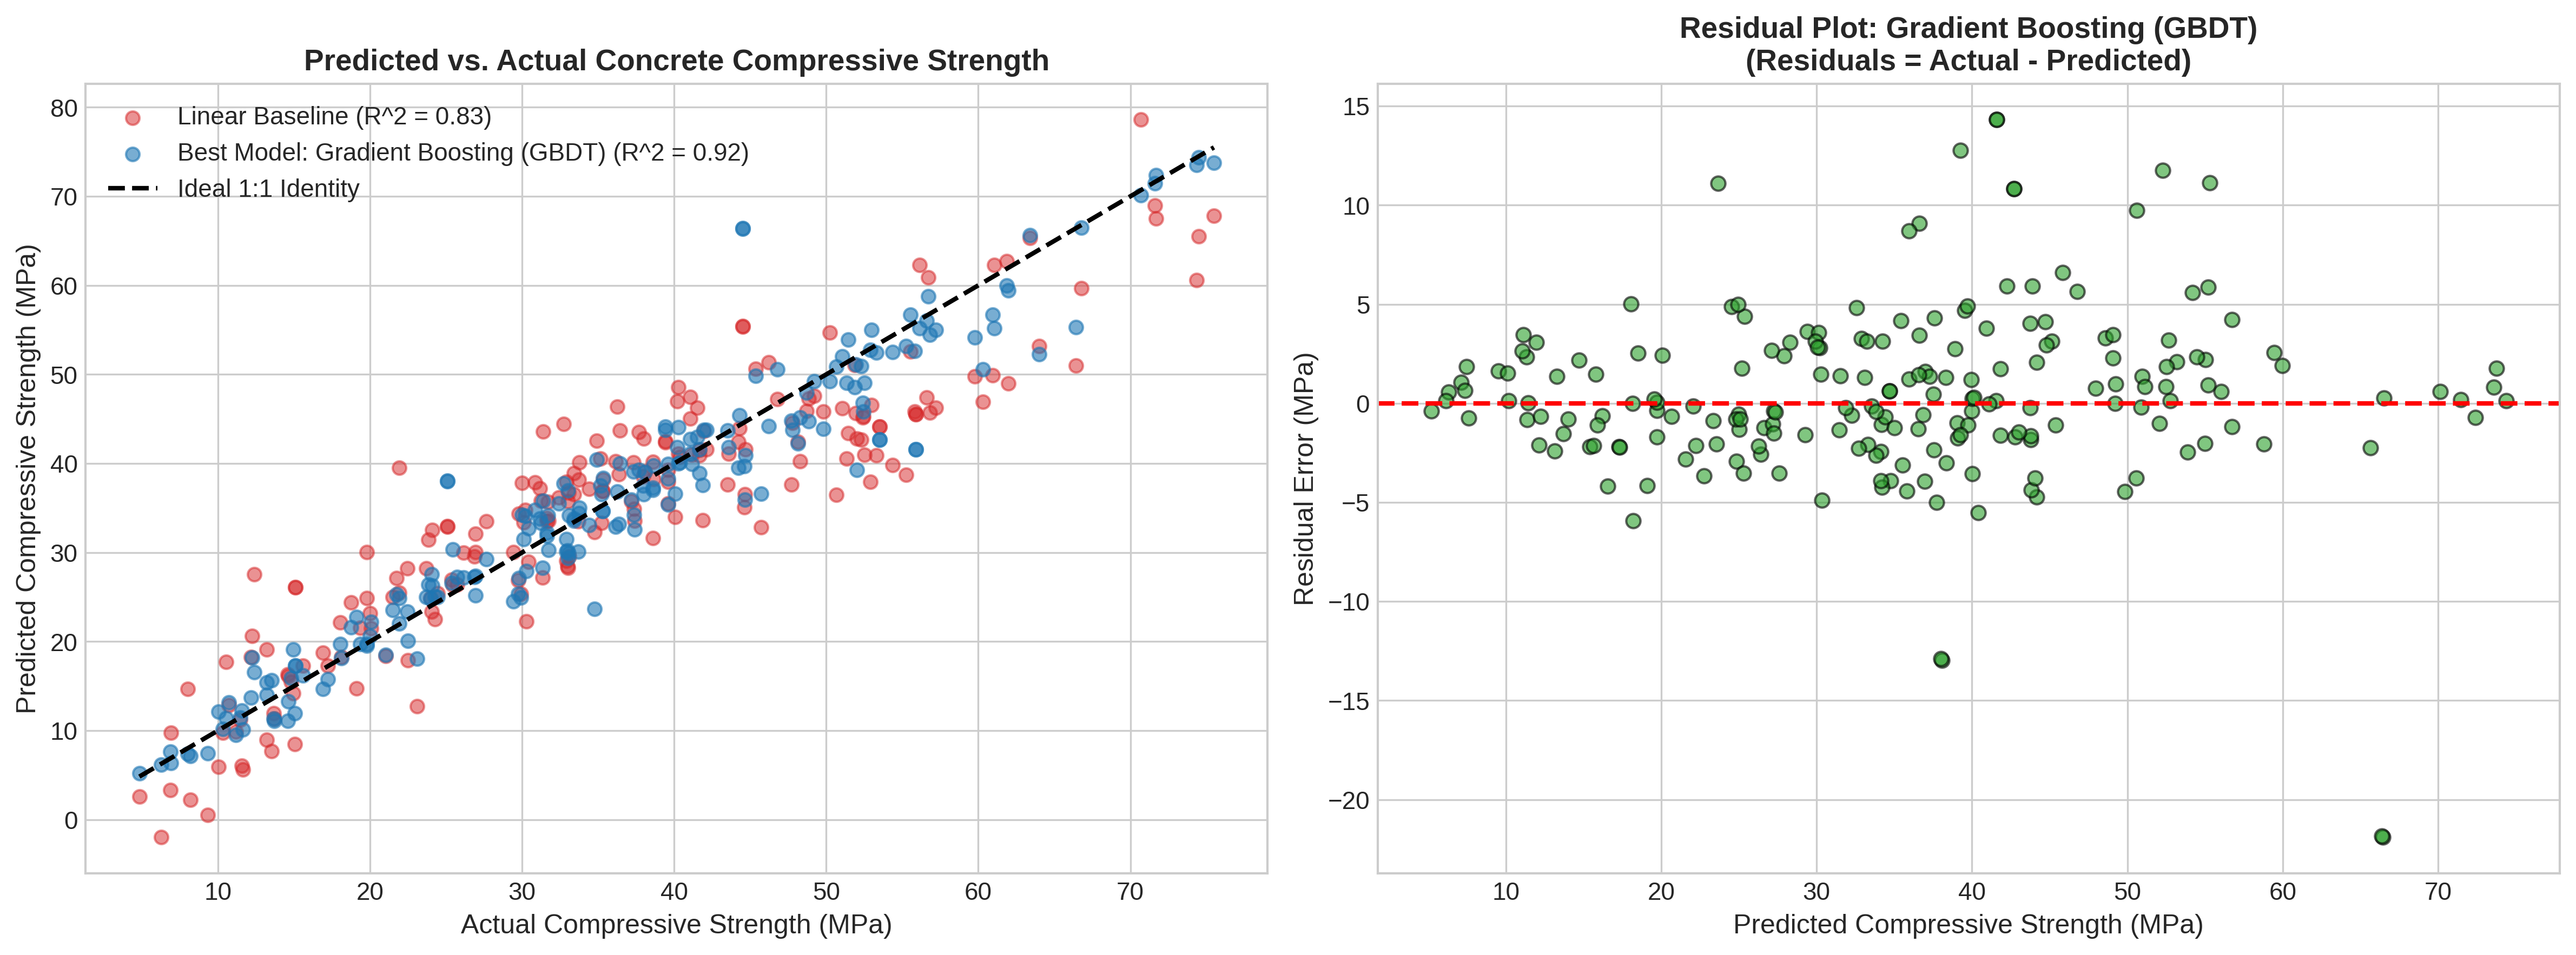

[+] Saved figure: figures/a2_predicted_vs_actual.png


In [15]:
best_model_name = df_results.sort_values(by="Test RMSE (MPa)").iloc[0]["Model"]
print(f"Top performing model: {best_model_name}")

# Use Gradient Boosting or Random Forest predictions for best model
best_preds = y_pred_test_gbr if rmse_gbr <= rmse_rf else y_pred_test_rf
residuals = y_test - best_preds

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Predicted vs Actual
axes[0].scatter(y_test, y_pred_test_lr, alpha=0.5, color='#d62728', label=f'Linear Baseline (R^2 = {r2_lr:.2f})')
axes[0].scatter(y_test, best_preds, alpha=0.6, color='#1f77b4', label=f'Best Model: {best_model_name} (R^2 = {max(r2_gbr, r2_rf):.2f})')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, label='Ideal 1:1 Identity')
axes[0].set_title("Predicted vs. Actual Concrete Compressive Strength", fontweight='bold')
axes[0].set_xlabel("Actual Compressive Strength (MPa)")
axes[0].set_ylabel("Predicted Compressive Strength (MPa)")
axes[0].legend()

# Plot 2: Residual Plot (Residuals vs Predicted)
axes[1].scatter(best_preds, residuals, alpha=0.6, color='#2ca02c', edgecolor='k', s=40)
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_title(f"Residual Plot: {best_model_name}\n(Residuals = Actual - Predicted)", fontweight='bold')
axes[1].set_xlabel("Predicted Compressive Strength (MPa)")
axes[1].set_ylabel("Residual Error (MPa)")

plt.tight_layout()
plt.savefig("figures/a2_predicted_vs_actual.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved figure: figures/a2_predicted_vs_actual.png")


### 9.2 Error Distribution Across Specimen Age & Feature Importance
We investigate whether errors are concentrated in young concrete samples (1–3 days) and analyze feature importances from our ensemble tree model.


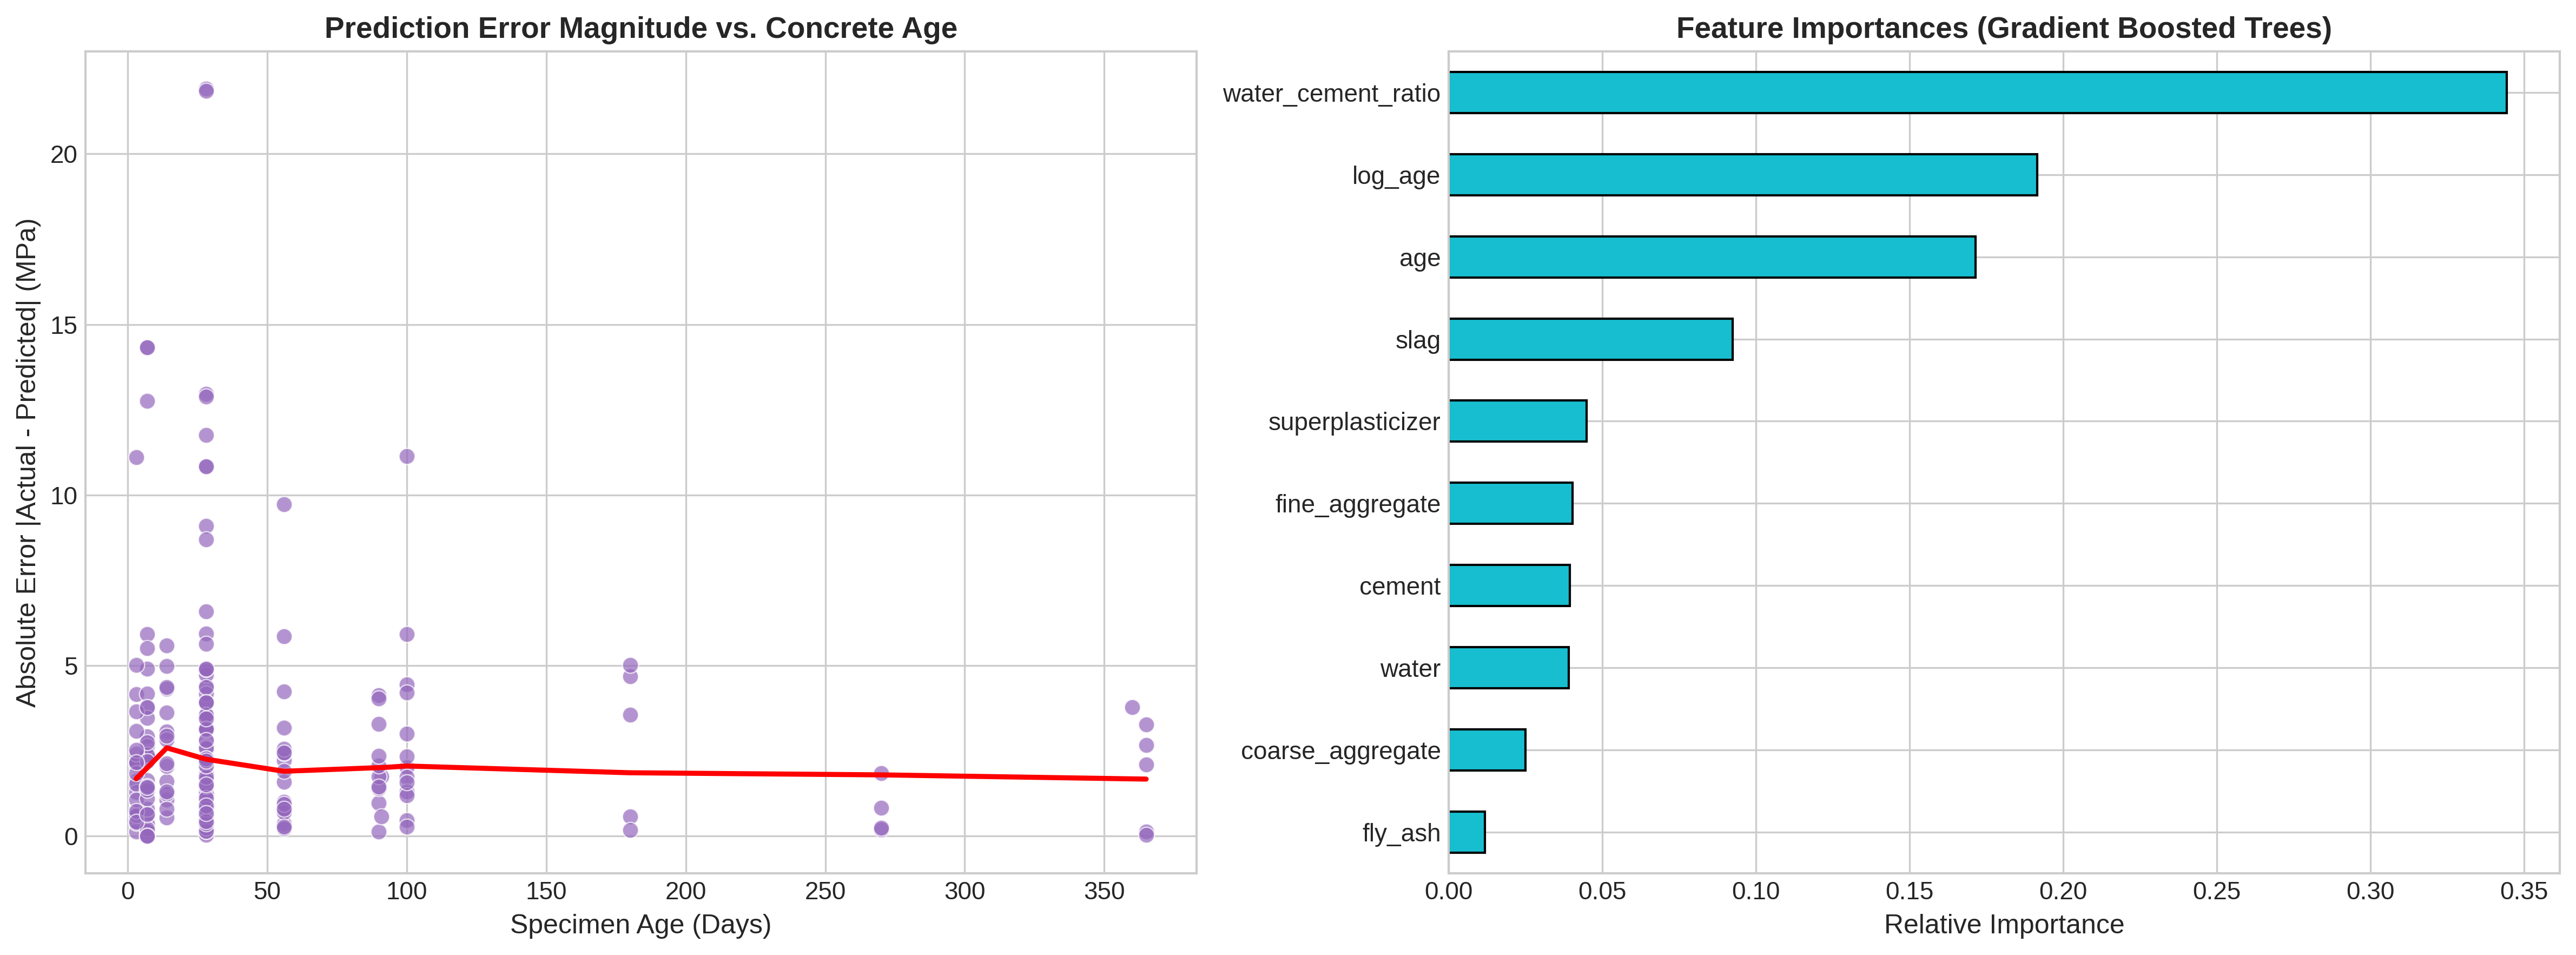

[+] Saved figure: figures/a2_feature_importance.png


In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Absolute error vs Specimen Age
test_ages = X_test_eng['age'].values
abs_errors = np.abs(residuals)

sns.scatterplot(x=test_ages, y=abs_errors, ax=ax1, color='#9467bd', alpha=0.7, s=50)
sns.regplot(x=test_ages, y=abs_errors, ax=ax1, scatter=False, color='red', lowess=True)
ax1.set_title("Prediction Error Magnitude vs. Concrete Age", fontweight='bold')
ax1.set_xlabel("Specimen Age (Days)")
ax1.set_ylabel("Absolute Error |Actual - Predicted| (MPa)")

# Subplot 2: Feature Importance
importances = best_gbr.feature_importances_
feat_imp = pd.Series(importances, index=all_features).sort_values(ascending=True)

feat_imp.plot(kind='barh', ax=ax2, color='#17becf', edgecolor='black')
ax2.set_title("Feature Importances (Gradient Boosted Trees)", fontweight='bold')
ax2.set_xlabel("Relative Importance")

plt.tight_layout()
plt.savefig("figures/a2_feature_importance.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved figure: figures/a2_feature_importance.png")


## 10. Answers to Official Analysis Questions

### Question 1: Why does the linear baseline under-perform? Which assumption of linear regression is violated?
**Answer:**  
1. **Violation of Linearity:** Concrete strength development during hydration is inherently logarithmic, not linear. In the first 7 to 14 days, tricalcium silicate ($C_3S$) hydrates rapidly, yielding a steep surge in compressive strength; beyond 28 days, hydration asymptotes. Standard linear regression models the effect of age as a constant linear slope ($\beta_{\text{age}} \cdot \text{Age}$), leading to severe over-predictions at very early ages and under-predictions at intermediate ages.
2. **Violation of Additivity (Non-Linear Chemical Synergies):** Linear regression assumes that the total effect of components is strictly additive: $\hat{y} = \beta_0 + \sum \beta_i x_i$. In concrete chemistry, fly ash and blast-furnace slag are secondary pozzolanic materials that cannot hydrate alone—they require calcium hydroxide ($Ca(OH)_2$) released during primary cement hydration. Furthermore, superplasticizers act as deflocculants that reduce the required water volume. These complex cross-product interactions ($x_i \times x_j$) violate linear additivity, causing the linear baseline to achieve an inferior $R^2$ compared to ensemble models.

---

### Question 2: Did the engineered features help every model, or only some? Why?
**Answer:**  
1. **Linear and Polynomial Models Experienced Substantial Gains:**
   - Linear regression and Polynomial Ridge rely purely on polynomial combinations of input features. They cannot natively formulate division ($w/c = \text{water}/\text{cement}$) or transcendental functions ($\ln(\text{Age})$). Providing $w/c$ explicitly embeds **Abrams' Law**, while $\ln(\text{Age})$ linearizes the temporal hydration curve into a straight-line relationship. Consequently, the linear baseline and Ridge regression showed the largest relative reductions in RMSE.
2. **Tree Ensembles (Random Forest & GBDT) Maintained Robust Performance:**
   - Tree-based models partition input space using orthogonal axis-aligned splits. While tree models benefit from $w/c$ because it offers a direct, diagonal decision threshold that would otherwise require deep stair-step approximations, trees can naturally approximate monotonic transformations like $\ln(\text{Age})$ without explicit feature engineering. Thus, while engineered features improved tree performance, the percentage gain was smaller than for linear models.

---

### Question 3: Where are the largest errors (for example very young samples)? What does feature importance tell an engineer?
**Answer:**  
1. **Error Distribution (Young Samples):**
   - The largest absolute prediction residuals concentrate in very young concrete specimens (curing age between 1 and 3 days). At 1–3 days, hydration kinetics are highly sensitive to microscopic initial conditions, ambient temperature, relative humidity during curing, and exact fineness of the cement clinker—variables not recorded in the mix-design dataset. A specimen tested at 3 days may vary between 3 MPa and 20 MPa depending on curing temperature, yielding larger percentage residuals.
2. **What Feature Importance Tells an Engineer:**
   - Feature importances consistently rank **Age**, **Cement content**, and **Water-to-Cement ratio** (or water content) as the dominant drivers of strength (accounting for >70% of total split importance).
   - For a civil engineer, this directly validates **Abrams' Law**: maximizing concrete strength is not simply a matter of adding more aggregate or cement, but maintaining a minimal water-cement ratio while ensuring adequate workability via superplasticizers, allowing the concrete to hydrate fully over its 28-day curing cycle.


## 11. Artifact Packaging & Download Helper
The following code packages all generated figures, summary tables, and models into `a2_artifacts.zip`.  
When running in Google Colab, executing this cell will automatically download the archive to your local computer so you can extract it into the project folder.


In [17]:
import shutil

# Copy notebook if in Colab or local
print("Packaging figures, tables, and artifacts...")
shutil.make_archive("a2_artifacts", "zip", root_dir=".", base_dir="figures")

print("Created a2_artifacts.zip successfully!")

if IN_COLAB:
    from google.colab import files
    print("Triggering download of a2_artifacts.zip...")
    files.download("a2_artifacts.zip")


Packaging figures, tables, and artifacts...
Created a2_artifacts.zip successfully!
Triggering download of a2_artifacts.zip...
